# Member 3: Neural Network for MSFT (Advanced level)

**Stock:** MSFT | **Target:** next-day log return | **Walk-forward:** INITIAL_TRAIN = 1000, TEST_SIZE = 63, 29 folds, 1,781 test days | **Seed:** 42

Method follows Notebook 6: scalers fitted on the fitting block only, the last 15% of each training block is the validation block (never shuffled), early stopping with the best weights restored, and the zero-forecast baseline printed next to the validation loss. Tuning uses only the first 1,000 days.

**Output files:** `data/nn_tuning.csv`, `data/nn_seeds.csv`, `data/predictions_nn.csv`, `data/dm_results_nn.csv` (plus `data/nn_seeds_summary.csv` and `data/nn_metrics.csv`).

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import sys, time, pickle, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler

import keras
from tslab import config
from tslab.data import load_market_data
from tslab.features import make_dataset, check_no_lookahead, ALL_FEATURES
from tslab.validation import walk_forward_splits
from tslab.metrics import (compare_models, diebold_mariano, dm_verdict,
                           directional_accuracy_test, out_of_sample_r2, rmse)
from tslab.nnutils import (set_seed, make_windows, BUILDERS, fit_with_early_stopping, predict_returns)

warnings.filterwarnings("ignore")
%matplotlib inline

print("Python:", sys.version.split()[0], "| Keras:", keras.__version__, "| backend:", keras.backend.backend())
print("Interpreter:", sys.executable)

Python: 3.11.18 | Keras: 3.15.1 | backend: tensorflow
Interpreter: /Users/noellamuya/Desktop/BI2/TimeSeriesForecasting-C1/.venv-nn/bin/python


## 1. Settings

In [2]:
SEED = config.SEED                 # 42
ARCH = "GRU"                       # one recurrent layer; "LSTM" also works with the same options
VALIDATION_SHARE = 0.15            # last 15% of each training block = validation, never shuffled
MAX_EPOCHS = 50
PATIENCE = 5
BATCH_SIZE = 32
SEEDS = [42, 43, 44]

# Tuning grid: three hyperparameters (window, units, dropout) = 18 runs
WINDOWS = [10, 20, 40]
UNITS = [16, 32, 64]
DROPOUTS = [0.0, 0.2]

DATA_DIR = Path("data"); DATA_DIR.mkdir(exist_ok=True)
CACHE_DIR = DATA_DIR / "nn_cache"; CACHE_DIR.mkdir(exist_ok=True)

assert config.INITIAL_TRAIN == 1000 and config.TEST_SIZE == 63, "Settings differ from Notebook 4"
print("INITIAL_TRAIN =", config.INITIAL_TRAIN, "| TEST_SIZE =", config.TEST_SIZE, "| SEED =", SEED)

INITIAL_TRAIN = 1000 | TEST_SIZE = 63 | SEED = 42


## 2. Data: the same 47-feature modelling table as Notebook 4

In [3]:
frame = load_market_data()
dataset = make_dataset(frame, horizon=1)
dataset = dataset.dropna(subset=["target_return"])        # same as Notebook 4

features = dataset[ALL_FEATURES].values
target = dataset["target_return"].values
print("Rows:", len(dataset), "| features:", len(ALL_FEATURES))
print("First day:", dataset.index[0].date(), "| last day with a known target:", dataset.index[-1].date())

# Look-ahead test on the features (rule 6)
check_no_lookahead(frame, n_checks=8)
print("PASSED: none of the features changes when the future is removed.")

Loaded 2981 trading days of MSFT, 2015-01-02 to 2026-11-09, with 7 predictor series.
Rows: 2781 | features: 47
First day: 2015-10-16 | last day with a known target: 2026-11-06
PASSED: none of the features changes when the future is removed.


## 3. Walk-forward folds (identical to Notebook 4)

Windows: a window ending on row r holds the features of rows r-N+1 ... r, and its label is the return of day r+1 (the `target_return` stored on row r). No window uses any feature from after row r.

In [4]:
splits = list(walk_forward_splits(len(dataset), config.INITIAL_TRAIN, config.TEST_SIZE))

def split_bounds(s):
    """Return (train_end, test_end) as row positions, whatever form the split takes."""
    train_idx, test_idx = np.asarray(s[0]), np.asarray(s[1])
    return int(train_idx[-1]) + 1, int(test_idx[-1]) + 1

BOUNDS = [split_bounds(s) for s in splits]
n_test = sum(e - t for t, e in BOUNDS)
print("Folds:", len(BOUNDS), "| test days:", n_test)
assert len(BOUNDS) == 29 and n_test == 1781, "Folds do not match Notebook 4 (29 folds, 1,781 days)"
print("First fold: train rows 0-%d, test rows %d-%d" % (BOUNDS[0][0]-1, BOUNDS[0][0], BOUNDS[0][1]-1))

Folds: 29 | test days: 1781
First fold: train rows 0-999, test rows 1000-1062


## 4. One training run (shared by tuning, seeds and walk-forward)

Fitting rows are the first 85% of the training block and validation rows are the last 15%. The scaler and the target scale come from the fitting rows only.

In [5]:
def build_model(window, units, dropout):
    return BUILDERS[ARCH](window, len(ALL_FEATURES), units=units, dropout=dropout)

def train_block(train_end, test_end, window, units, dropout, seed):
    """
    Train one network on rows [0, train_end). Predict the log returns of rows [train_end, test_end).
    Returns (predictions, best_val_loss, zero_val_loss). If test_end <= train_end nothing is predicted.
    """
    fit_end = int(train_end * (1 - VALIDATION_SHARE))
    scaler = StandardScaler().fit(features[:fit_end])                 # fitting rows only
    f_scaled = scaler.transform(features[:test_end])
    t_scale = target[:fit_end].std()
    t_scaled = target[:test_end] / t_scale

    X_all, y_all = make_windows(f_scaled, t_scaled, window)
    ends = np.arange(window - 1, test_end)                            # row on which each window ends
    in_fit = ends < fit_end
    in_val = (ends >= fit_end) & (ends < train_end)
    in_test = ends >= train_end

    set_seed(seed)
    keras.backend.clear_session()
    model = build_model(window, units, dropout)
    history = fit_with_early_stopping(model, X_all[in_fit], y_all[in_fit], X_all[in_val], y_all[in_val],
                                      epochs=MAX_EPOCHS, batch_size=BATCH_SIZE, patience=PATIENCE)
    best_val = float(min(history.history["val_loss"]))
    zero_val = float(np.mean(y_all[in_val] ** 2))                     # always predicting zero
    preds = predict_returns(model, X_all[in_test]) * t_scale if in_test.any() else np.array([])
    return preds, best_val, zero_val

## 5. Tuning on the first 1,000 days only

Train on the first 85% of rows 0-999, validate on the last 15%, never shuffled. Nothing after day 1,000 is touched. The zero-forecast loss is the validation loss of always predicting 0 on the same block.

In [6]:
tuning_file = DATA_DIR / "nn_tuning.csv"
if tuning_file.exists():
    tuning = pd.read_csv(tuning_file)
    print("Loaded existing tuning table")
else:
    rows = []
    t0 = time.time()
    for window, units, dropout in itertools.product(WINDOWS, UNITS, DROPOUTS):
        _, best_val, zero_val = train_block(config.INITIAL_TRAIN, config.INITIAL_TRAIN, window, units, dropout, SEED)
        rows.append({"window": window, "units": units, "dropout": dropout,
                     "validation loss": best_val, "zero-forecast validation loss": zero_val})
        print(f"w={window:2d} u={units:2d} d={dropout}: val {best_val:.4f} vs zero {zero_val:.4f}  ({time.time()-t0:.0f}s)")
    tuning = pd.DataFrame(rows)
    tuning.to_csv(tuning_file, index=False)

tuning = tuning.sort_values("validation loss").reset_index(drop=True)
display(tuning.round(4))

best = tuning.iloc[0]
BEST = dict(window=int(best["window"]), units=int(best["units"]), dropout=float(best["dropout"]))
print("Best setting:", BEST)
print(f"Validation loss {best['validation loss']:.4f} vs zero-forecast loss {best['zero-forecast validation loss']:.4f}")
if best["validation loss"] >= 0.99 * best["zero-forecast validation loss"]:
    print("The network is NOT clearly better than always predicting zero on the validation block.")
else:
    print("The network is below the zero-forecast loss on the validation block.")

w=10 u=16 d=0.0: val 0.7975 vs zero 0.8009  (15s)
w=10 u=16 d=0.2: val 0.7944 vs zero 0.8009  (31s)
w=10 u=32 d=0.0: val 0.7748 vs zero 0.8009  (38s)
w=10 u=32 d=0.2: val 0.8033 vs zero 0.8009  (45s)
w=10 u=64 d=0.0: val 0.7693 vs zero 0.8009  (50s)
w=10 u=64 d=0.2: val 0.8437 vs zero 0.8009  (57s)
w=20 u=16 d=0.0: val 0.8010 vs zero 0.8009  (63s)
w=20 u=16 d=0.2: val 0.8015 vs zero 0.8009  (70s)
w=20 u=32 d=0.0: val 0.7735 vs zero 0.8009  (76s)
w=20 u=32 d=0.2: val 0.8042 vs zero 0.8009  (82s)
w=20 u=64 d=0.0: val 0.7516 vs zero 0.8009  (89s)
w=20 u=64 d=0.2: val 0.8194 vs zero 0.8009  (101s)
w=40 u=16 d=0.0: val 0.7928 vs zero 0.8009  (113s)
w=40 u=16 d=0.2: val 0.7992 vs zero 0.8009  (125s)
w=40 u=32 d=0.0: val 0.7699 vs zero 0.8009  (136s)
w=40 u=32 d=0.2: val 0.8005 vs zero 0.8009  (145s)
w=40 u=64 d=0.0: val 0.7531 vs zero 0.8009  (157s)
w=40 u=64 d=0.2: val 0.8282 vs zero 0.8009  (177s)


,window,units,dropout,validation loss,zero-forecast validation loss
0,20,64,0.0,0.7516,0.8009
1,40,64,0.0,0.7531,0.8009
2,10,64,0.0,0.7693,0.8009
3,40,32,0.0,0.7699,0.8009
4,20,32,0.0,0.7735,0.8009
5,10,32,0.0,0.7748,0.8009
6,40,16,0.0,0.7928,0.8009
7,10,16,0.2,0.7944,0.8009
8,10,16,0.0,0.7975,0.8009
9,40,16,0.2,0.7992,0.8009


Best setting: {'window': 20, 'units': 64, 'dropout': 0.0}
Validation loss 0.7516 vs zero-forecast loss 0.8009
The network is below the zero-forecast loss on the validation block.


## 6. Walk-forward over all 29 folds (saved after every fold, so you can stop and resume)

In [7]:
def tag_of(window, units, dropout, seed):
    return f"{ARCH} w{window} u{units} d{dropout:g} seed{seed}"

def walk_forward(window, units, dropout, seed):
    tag = tag_of(window, units, dropout, seed)
    cache = CACHE_DIR / (tag.replace(" ", "_") + ".pkl")
    state = pickle.load(open(cache, "rb")) if cache.exists() else {}
    t0 = time.time()
    for k, (train_end, test_end) in enumerate(BOUNDS, start=1):
        if k in state:
            continue
        preds, best_val, zero_val = train_block(train_end, test_end, window, units, dropout, seed)
        assert len(preds) == test_end - train_end
        state[k] = {"preds": preds, "best_val": best_val, "zero_val": zero_val}
        pickle.dump(state, open(cache, "wb"))
        print(f"  {tag} fold {k}/{len(BOUNDS)}  ({time.time()-t0:.0f}s)")
    series = pd.Series(np.nan, index=dataset.index, name=tag)
    for k, (train_end, test_end) in enumerate(BOUNDS, start=1):
        series.iloc[train_end:test_end] = state[k]["preds"]
    return series, pd.DataFrame(state).T

In [8]:
# Best setting with seeds 42, 43, 44 (start this early: it is the slow part)
nn_preds, nn_details = {}, {}
for seed in SEEDS:
    s, d = walk_forward(**BEST, seed=seed)
    nn_preds[s.name], nn_details[s.name] = s, d
    print("Finished", s.name)

  GRU w20 u64 d0 seed42 fold 1/29  (9s)
  GRU w20 u64 d0 seed42 fold 2/29  (20s)
  GRU w20 u64 d0 seed42 fold 3/29  (44s)
  GRU w20 u64 d0 seed42 fold 4/29  (53s)
  GRU w20 u64 d0 seed42 fold 5/29  (63s)
  GRU w20 u64 d0 seed42 fold 6/29  (72s)
  GRU w20 u64 d0 seed42 fold 7/29  (83s)
  GRU w20 u64 d0 seed42 fold 8/29  (95s)
  GRU w20 u64 d0 seed42 fold 9/29  (105s)
  GRU w20 u64 d0 seed42 fold 10/29  (116s)
  GRU w20 u64 d0 seed42 fold 11/29  (126s)
  GRU w20 u64 d0 seed42 fold 12/29  (140s)
  GRU w20 u64 d0 seed42 fold 13/29  (155s)
  GRU w20 u64 d0 seed42 fold 14/29  (167s)
  GRU w20 u64 d0 seed42 fold 15/29  (177s)
  GRU w20 u64 d0 seed42 fold 16/29  (186s)
  GRU w20 u64 d0 seed42 fold 17/29  (201s)
  GRU w20 u64 d0 seed42 fold 18/29  (214s)
  GRU w20 u64 d0 seed42 fold 19/29  (227s)
  GRU w20 u64 d0 seed42 fold 20/29  (242s)
  GRU w20 u64 d0 seed42 fold 21/29  (259s)
  GRU w20 u64 d0 seed42 fold 22/29  (269s)
  GRU w20 u64 d0 seed42 fold 23/29  (283s)
  GRU w20 u64 d0 seed42 fold 

## 7. Seeds: how much does the result depend on luck?

In [9]:
actual_all = dataset["target_return"]
mask = pd.concat(nn_preds, axis=1).notna().all(axis=1)
print("Scored days:", int(mask.sum()))

seed_rows = []
for seed in SEEDS:
    name = tag_of(**BEST, seed=seed)
    seed_rows.append({"setting": f"{ARCH} w{BEST['window']} u{BEST['units']} d{BEST['dropout']:g}",
                      "seed": seed, "RMSE": rmse(actual_all[mask], nn_preds[name][mask])})
seeds = pd.DataFrame(seed_rows)
seeds.to_csv(DATA_DIR / "nn_seeds.csv", index=False)

naive_rmse = rmse(actual_all[mask], np.zeros(int(mask.sum())))
summary = pd.DataFrame({"mean RMSE": [seeds["RMSE"].mean()], "std": [seeds["RMSE"].std()],
                        "max - min": [seeds["RMSE"].max() - seeds["RMSE"].min()], "naive RMSE": [naive_rmse]})
summary.to_csv(DATA_DIR / "nn_seeds_summary.csv", index=False)
display(seeds.round(6)); display(summary.round(6))

Scored days: 1781


,setting,seed,RMSE
0,GRU w20 u64 d0,42,0.019427
1,GRU w20 u64 d0,43,0.019430
2,GRU w20 u64 d0,44,0.019339


,mean RMSE,std,max - min,naive RMSE
0,0.019399,0.000052,0.000091,0.018854


## 8. Predictions file for Member 4

In [10]:
# One column per seed, plus the average of the three seeds (an ensemble)
pred_nn = pd.concat(nn_preds, axis=1)
ens_name = f"{ARCH} w{BEST['window']} u{BEST['units']} d{BEST['dropout']:g} 3-seed average"
pred_nn[ens_name] = pred_nn.mean(axis=1, skipna=False)
pred_nn.index.name = "Date"
pred_nn.to_csv(DATA_DIR / "predictions_nn.csv", index_label="Date")

# Check against Member 4's file: same dates, no empty cells on the test days
ml_file = Path("outputs/predictions_ml.csv")
pred_ml = pd.read_csv(ml_file, index_col=0, parse_dates=True)
ml_days = pred_ml["Ridge"].dropna().index
nn_days = pred_nn.dropna().index
assert len(nn_days) == 1781, f"Expected 1781 scored days, got {len(nn_days)}"
assert (nn_days == ml_days).all(), "NN test days differ from predictions_ml.csv"
assert pred_nn.loc[ml_days].notna().all().all(), "Empty cells on test days"
print("OK:", len(nn_days), "test days match outputs/predictions_ml.csv |", nn_days[0].date(), "to", nn_days[-1].date())
print("Columns:", list(pred_nn.columns))

OK: 1781 test days match outputs/predictions_ml.csv | 2019-10-08 to 2026-11-06
Columns: ['GRU w20 u64 d0 seed42', 'GRU w20 u64 d0 seed43', 'GRU w20 u64 d0 seed44', 'GRU w20 u64 d0 3-seed average']


## 9. Scores against naive, and Diebold-Mariano (same layout as `dm_results_ml.csv`)

In [11]:
all_preds = {c: pred_nn[c] for c in pred_nn.columns}
for name in ["Ridge", "Gradient boosting"]:
    all_preds[name] = pred_ml[name].reindex(dataset.index)

scores = compare_models(dataset, all_preds)
display(scores.round(4))
scores.to_csv(DATA_DIR / "nn_metrics.csv")

scored_rows = pd.concat(all_preds, axis=1).dropna().index
actual = dataset.loc[scored_rows, "target_return"]

rows = []
for name in pred_nn.columns:
    stat, p = diebold_mariano(actual, all_preds[name].loc[scored_rows], np.zeros(len(scored_rows)))
    hit, p_dir = directional_accuracy_test(actual, all_preds[name].loc[scored_rows])
    rows.append({"Model": name, "DM statistic vs naive": stat, "DM p-value": p, "Verdict": dm_verdict(stat, p),
                 "Hit rate": hit, "Hit rate p-value (vs 50%)": p_dir})
dm_nn = pd.DataFrame(rows).set_index("Model").round(4)
dm_nn.to_csv(DATA_DIR / "dm_results_nn.csv")

ref = pd.read_csv("outputs/dm_results_ml.csv", index_col=0)
assert list(dm_nn.columns) == list(ref.columns), (list(dm_nn.columns), list(ref.columns))
dm_nn

,RMSE ($),MAE ($),MAPE (%),Directional accuracy,Out-of-sample R2 (returns)
Naive (no change),5.7884,3.9939,1.3017,NaN,0.0000
GRU w20 u64 d0 seed42,5.9363,4.1557,1.3592,0.5065,-0.0618
GRU w20 u64 d0 seed43,5.9799,4.2237,1.3783,0.4935,-0.0620
GRU w20 u64 d0 seed44,5.9803,4.2043,1.3665,0.4952,-0.0521
GRU w20 u64 d0 3-seed average,5.8720,4.1096,1.3423,0.4907,-0.0276
Ridge,5.8793,4.0724,1.3261,0.5065,-0.0166
Gradient boosting,5.8349,4.0318,1.3127,0.5199,-0.0071


,DM statistic vs naive,DM p-value,Verdict,Hit rate,Hit rate p-value (vs 50%)
Model,,,,,
GRU w20 u64 d0 seed42,3.8731,0.0001,Significantly WORSE than naive,0.5065,0.6022
GRU w20 u64 d0 seed43,3.9219,0.0001,Significantly WORSE than naive,0.4935,0.6022
GRU w20 u64 d0 seed44,2.8822,0.0040,Significantly WORSE than naive,0.4952,0.7046
GRU w20 u64 d0 3-seed average,2.1436,0.0322,Significantly WORSE than naive,0.4907,0.4483


## 10. Validation loss versus the zero-forecast loss, per fold

,network validation loss,zero-forecast validation loss
mean,1.3415,1.2834
min,0.5210,0.5073
max,4.8426,4.8116


Folds where the network's validation loss was below the zero-forecast loss: 7%


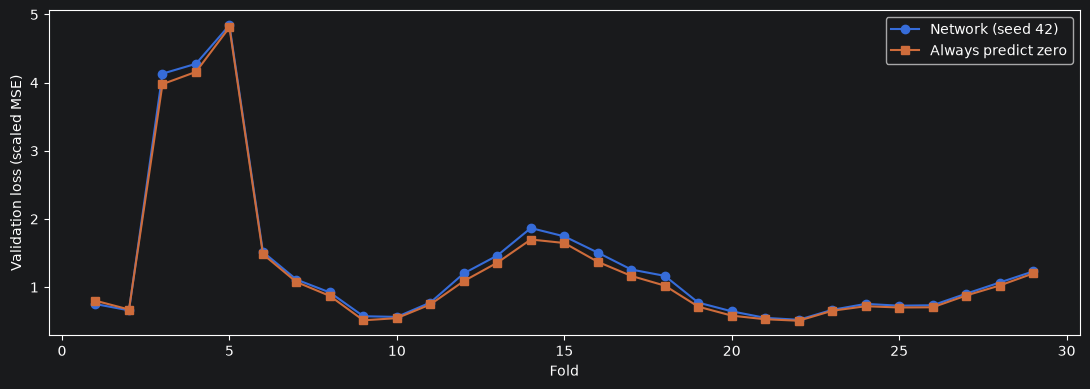

In [12]:
first = nn_details[tag_of(**BEST, seed=SEEDS[0])]
fold_table = pd.DataFrame({"network validation loss": first["best_val"].astype(float),
                           "zero-forecast validation loss": first["zero_val"].astype(float)})
display(fold_table.describe().loc[["mean", "min", "max"]].round(4))
share_better = (fold_table.iloc[:, 0] < fold_table.iloc[:, 1]).mean()
print(f"Folds where the network's validation loss was below the zero-forecast loss: {share_better:.0%}")

plt.figure(figsize=(11, 4))
plt.plot(fold_table.index, fold_table.iloc[:, 0], marker="o", label="Network (seed 42)")
plt.plot(fold_table.index, fold_table.iloc[:, 1], marker="s", label="Always predict zero")
plt.xlabel("Fold"); plt.ylabel("Validation loss (scaled MSE)"); plt.legend(); plt.tight_layout(); plt.show()

## 11. Written answers (edit after reading your own numbers)

**Did the network beat naive?** No. It was significantly worse. The Diebold-Mariano test against naive gave p = 0.0001, 0.0001 and 0.004 for seeds 42, 43 and 44, and p = 0.032 for the 3-seed average. The out-of-sample R² was negative for all of them (-0.052 to -0.062 for single seeds and -0.028 for the average), and the directional accuracy of about 49% to 51% was not different from a coin flip (p = 0.45 to 0.70). This differs from Ridge and gradient boosting, which were not significantly different from naive.

**What did the zero-forecast baseline show?** On the tuning block, the best network reached a validation loss of 0.752 against 0.801 for always predicting zero, about 6% lower. This is a small edge on one short block and it did not carry over to the walk-forward test, so the network learned little that helps beyond predicting no change.

**What did the seeds show?** The RMSE was 0.01943, 0.01943 and 0.01934 for seeds 42, 43 and 44, a spread of 0.00009. That is small compared with the 0.0005 gap to naive, so the result is stable and not down to luck: the network is consistently slightly worse than naive.

**Hardware note:** trained on the CPU of a Mac. There was no NVIDIA GPU, so the optional GPU part was not done.